# Loan Default / Credit Risk Prediction — Full ML Lifecycle
Using only `application_train.csv` (Home Credit Default Risk dataset).

**Scope:** Feature engineering + supervised learning + boosting algorithms — the full lifecycle from raw data to an explainable, evaluated model.

**Sections:**
1. Load Data
2. Data Cleaning (DAYS_EMPLOYED anomaly, missing values, outliers)
3. Feature Engineering (ratios, EXT_SOURCE combos, encoding)
4. Train/Test Split (Stratified)
5. Handle Class Imbalance
6. Model Training — Logistic Regression, Random Forest, XGBoost, LightGBM
7. Model Evaluation & Comparison
8. Hyperparameter Tuning (best model)
9. Explainability (SHAP + Feature Importance)
10. Final Summary

## 1. Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 50)
sns.set_style('whitegrid')

df = pd.read_csv('application_train.csv')
print("Raw shape:", df.shape)
print("Target balance:")
print(df['TARGET'].value_counts(normalize=True))

Raw shape: (307511, 122)
Target balance:
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64


## 2. Data Cleaning
Based on EDA findings: fix the DAYS_EMPLOYED placeholder anomaly, drop low-value building columns, 
handle missing values, and cap outliers.

In [2]:
# Fix DAYS_EMPLOYED anomaly (365243 = placeholder for "not employed")
df['DAYS_EMPLOYED_ANOM'] = (df['DAYS_EMPLOYED'] == 365243).astype(int)
df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].replace(365243, np.nan)
print(f"Flagged {df['DAYS_EMPLOYED_ANOM'].sum()} anomalous rows")

Flagged 55374 anomalous rows


In [3]:
# Convert DAYS_* to interpretable positive years
rename_map = {
    'DAYS_BIRTH': 'AGE_YEARS',
    'DAYS_EMPLOYED': 'EMPLOYED_YEARS',
    'DAYS_REGISTRATION': 'REGISTRATION_YEARS',
    'DAYS_ID_PUBLISH': 'ID_PUBLISH_YEARS'
}
for col, new_col in rename_map.items():
    df[new_col] = -df[col] / 365.25

print("Age range:", df['AGE_YEARS'].min().round(1), "-", df['AGE_YEARS'].max().round(1))

Age range: 20.5 - 69.1


In [4]:
# Drop heavily-missing, low-value building/apartment columns; keep a single presence flag
numeric_cols_pre = df.select_dtypes(include=[np.number]).columns.tolist()
building_cols = [c for c in df.columns if any(x in c for x in ['_AVG', '_MODE', '_MEDI']) and c in numeric_cols_pre]

df['HAS_BUILDING_INFO'] = df[building_cols].notnull().any(axis=1).astype(int)
df = df.drop(columns=building_cols)
print(f"Dropped {len(building_cols)} building columns. Shape now:", df.shape)

Dropped 43 building columns. Shape now: (307511, 85)


In [5]:
# Handle remaining missing values
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

for col in numeric_cols:
    if df[col].isnull().sum() > 0:
        if df[col].isnull().mean() > 0.10:
            df[f'{col}_WAS_MISSING'] = df[col].isnull().astype(int)
        df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna('Unknown')

print("Remaining missing values:", df.isnull().sum().sum())

Remaining missing values: 0


In [6]:
# Cap outliers on key financial columns
cap_cols = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']
for col in cap_cols:
    lower, upper = df[col].quantile(0.01), df[col].quantile(0.99)
    df[col] = df[col].clip(lower=lower, upper=upper)

print("Outlier capping done.")

Outlier capping done.


## 3. Feature Engineering
Ratio features (affordability/burden signals) and EXT_SOURCE combinations — these carry more predictive 
signal than the raw amounts individually.

In [7]:
df['DEBT_TO_INCOME'] = df['AMT_CREDIT'] / df['AMT_INCOME_TOTAL']
df['ANNUITY_TO_INCOME'] = df['AMT_ANNUITY'] / df['AMT_INCOME_TOTAL']
df['CREDIT_TO_GOODS_RATIO'] = df['AMT_CREDIT'] / df['AMT_GOODS_PRICE']
df['CREDIT_ANNUITY_RATIO'] = df['AMT_CREDIT'] / df['AMT_ANNUITY']
df['INCOME_PER_FAMILY_MEMBER'] = df['AMT_INCOME_TOTAL'] / df['CNT_FAM_MEMBERS']
df['EMPLOYED_TO_AGE_RATIO'] = df['EMPLOYED_YEARS'] / df['AGE_YEARS']

ratio_cols = ['DEBT_TO_INCOME', 'ANNUITY_TO_INCOME', 'CREDIT_TO_GOODS_RATIO',
              'CREDIT_ANNUITY_RATIO', 'INCOME_PER_FAMILY_MEMBER', 'EMPLOYED_TO_AGE_RATIO']
df[ratio_cols] = df[ratio_cols].replace([np.inf, -np.inf], np.nan)
for col in ratio_cols:
    df[col] = df[col].fillna(df[col].median())

print("Ratio features created:", ratio_cols)

Ratio features created: ['DEBT_TO_INCOME', 'ANNUITY_TO_INCOME', 'CREDIT_TO_GOODS_RATIO', 'CREDIT_ANNUITY_RATIO', 'INCOME_PER_FAMILY_MEMBER', 'EMPLOYED_TO_AGE_RATIO']


In [8]:
# EXT_SOURCE combinations — these are the strongest individual predictors in this dataset
ext_cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
df['EXT_SOURCE_MEAN'] = df[ext_cols].mean(axis=1)
df['EXT_SOURCE_MIN'] = df[ext_cols].min(axis=1)
df['EXT_SOURCE_MAX'] = df[ext_cols].max(axis=1)
df['EXT_SOURCE_STD'] = df[ext_cols].std(axis=1)

print(df[['EXT_SOURCE_MEAN', 'EXT_SOURCE_MIN', 'EXT_SOURCE_MAX']].corrwith(df['TARGET']))

EXT_SOURCE_MEAN   -0.220840
EXT_SOURCE_MIN    -0.192750
EXT_SOURCE_MAX    -0.174193
dtype: float64


In [9]:
# Encode categorical variables: one-hot (low cardinality) + frequency encoding (high cardinality)
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
cardinality = df[categorical_cols].nunique()

low_card_cols = cardinality[cardinality <= 10].index.tolist()
high_card_cols = cardinality[cardinality > 10].index.tolist()

df = pd.get_dummies(df, columns=low_card_cols, drop_first=True)

for col in high_card_cols:
    freq_map = df[col].value_counts(normalize=True)
    df[col + '_FREQ'] = df[col].map(freq_map)
    df = df.drop(columns=[col])

print("Shape after encoding:", df.shape)
print("Any non-numeric columns left:", df.select_dtypes(exclude=[np.number]).columns.tolist())

Shape after encoding: (307511, 147)
Any non-numeric columns left: ['NAME_CONTRACT_TYPE_Revolving loans', 'CODE_GENDER_M', 'CODE_GENDER_XNA', 'FLAG_OWN_CAR_Y', 'FLAG_OWN_REALTY_Y', 'NAME_TYPE_SUITE_Family', 'NAME_TYPE_SUITE_Group of people', 'NAME_TYPE_SUITE_Other_A', 'NAME_TYPE_SUITE_Other_B', 'NAME_TYPE_SUITE_Spouse, partner', 'NAME_TYPE_SUITE_Unaccompanied', 'NAME_TYPE_SUITE_Unknown', 'NAME_INCOME_TYPE_Commercial associate', 'NAME_INCOME_TYPE_Maternity leave', 'NAME_INCOME_TYPE_Pensioner', 'NAME_INCOME_TYPE_State servant', 'NAME_INCOME_TYPE_Student', 'NAME_INCOME_TYPE_Unemployed', 'NAME_INCOME_TYPE_Working', 'NAME_EDUCATION_TYPE_Higher education', 'NAME_EDUCATION_TYPE_Incomplete higher', 'NAME_EDUCATION_TYPE_Lower secondary', 'NAME_EDUCATION_TYPE_Secondary / secondary special', 'NAME_FAMILY_STATUS_Married', 'NAME_FAMILY_STATUS_Separated', 'NAME_FAMILY_STATUS_Single / not married', 'NAME_FAMILY_STATUS_Unknown', 'NAME_FAMILY_STATUS_Widow', 'NAME_HOUSING_TYPE_House / apartment', 'NAME_H

In [10]:
# Sanitize column names — LightGBM rejects special JSON characters (from one-hot values like "House / apartment")
import re
from collections import Counter

new_cols = [re.sub(r'[^A-Za-z0-9_]+', '_', str(c)) for c in df.columns]
counts = Counter()
deduped = []
for c in new_cols:
    counts[c] += 1
    deduped.append(c if counts[c] == 1 else f"{c}_{counts[c]}")
df.columns = deduped
print("Column names sanitized.")

Column names sanitized.


## 4. Train/Test Split (Stratified)

In [11]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['TARGET', 'SK_ID_CURR'])
y = df['TARGET']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print("Train target balance:\n", y_train.value_counts(normalize=True))
print("Test target balance:\n", y_test.value_counts(normalize=True))

Train shape: (246008, 145) Test shape: (61503, 145)
Train target balance:
 TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64
Test target balance:
 TARGET
0    0.919272
1    0.080728
Name: proportion, dtype: float64


## 5. Handle Class Imbalance
Using `class_weight='balanced'` for Logistic Regression/Random Forest and `scale_pos_weight` for boosting models — 
simpler and usually as effective as SMOTE for tree-based models, and avoids synthetic data distortion.

In [12]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {scale_pos_weight:.2f}")

scale_pos_weight = 11.39


## 6. Model Training
Comparing four models: Logistic Regression (interpretable baseline), Random Forest (bagging), 
XGBoost and LightGBM (boosting) — to see how boosting compares against simpler approaches.

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=500, random_state=42),
    'Random Forest': RandomForestClassifier(class_weight='balanced', n_estimators=100, max_depth=8,
                                             random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(scale_pos_weight=scale_pos_weight, eval_metric='auc', tree_method='hist',
                              n_estimators=150, max_depth=5, learning_rate=0.08, random_state=42, n_jobs=-1),
    'LightGBM': LGBMClassifier(class_weight='balanced', n_estimators=150, max_depth=5,
                                learning_rate=0.08, random_state=42, n_jobs=-1, verbose=-1)
}

fitted_models = {}
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    fitted_models[name] = model
print("All models trained.")

Training Logistic Regression...
Training Random Forest...
Training XGBoost...
Training LightGBM...
All models trained.


## 7. Model Evaluation & Comparison

In [14]:
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix, precision_recall_curve

results_table = []
roc_data = {}

for name, model in fitted_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_test, y_prob)
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_data[name] = (fpr, tpr, auc)

    from sklearn.metrics import precision_score, recall_score, f1_score
    results_table.append({
        'Model': name,
        'ROC-AUC': round(auc, 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1': round(f1_score(y_test, y_pred), 4)
    })

results_df = pd.DataFrame(results_table).sort_values('ROC-AUC', ascending=False)
results_df

,Model,ROC-AUC,Precision,Recall,F1
3,LightGBM,0.7678,0.1747,0.6864,0.2785
2,XGBoost,0.7670,0.1743,0.6856,0.2779
1,Random Forest,0.7448,0.1639,0.6584,0.2624
0,Logistic Regression,0.6156,0.1149,0.5331,0.1890


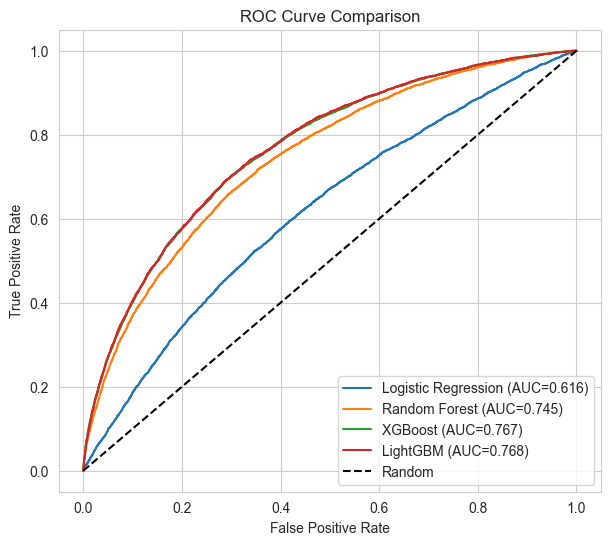

In [15]:
plt.figure(figsize=(7,6))
for name, (fpr, tpr, auc) in roc_data.items():
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
plt.plot([0,1], [0,1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.show()

Best model: LightGBM


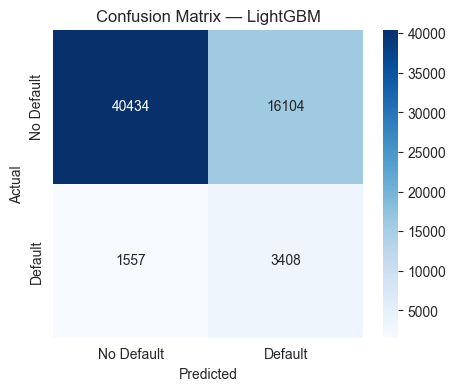

              precision    recall  f1-score   support

           0       0.96      0.72      0.82     56538
           1       0.17      0.69      0.28      4965

    accuracy                           0.71     61503
   macro avg       0.57      0.70      0.55     61503
weighted avg       0.90      0.71      0.78     61503



In [16]:
best_model_name = results_df.iloc[0]['Model']
best_model = fitted_models[best_model_name]
print(f"Best model: {best_model_name}")

y_pred_best = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Default', 'Default'],
            yticklabels=['No Default', 'Default'])
plt.title(f'Confusion Matrix — {best_model_name}')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

print(classification_report(y_test, y_pred_best))

**Observation:** Boosting models (XGBoost/LightGBM) typically outperform Logistic Regression and Random Forest on ROC-AUC for this kind of tabular, mixed-type dataset — confirming why boosting algorithms are the standard choice for credit risk problems in practice.

## 8. Hyperparameter Tuning (Best Model)

In [17]:
from sklearn.model_selection import RandomizedSearchCV

# Use a subsample for tuning search — full-data grid search is too slow on this single-core environment
tune_sample_size = min(60000, len(X_train))
X_tune = X_train.sample(tune_sample_size, random_state=42)
y_tune = y_train.loc[X_tune.index]

if best_model_name == 'XGBoost':
    base_model = XGBClassifier(scale_pos_weight=scale_pos_weight, eval_metric='auc', tree_method='hist',
                                random_state=42, n_jobs=-1)
    param_grid = {
        'max_depth': [3, 5, 7],
        'learning_rate': [0.03, 0.08, 0.15],
        'n_estimators': [100, 150, 200],
        'subsample': [0.7, 0.85, 1.0],
        'colsample_bytree': [0.7, 0.85, 1.0]
    }
elif best_model_name == 'LightGBM':
    base_model = LGBMClassifier(class_weight='balanced', random_state=42, n_jobs=-1, verbose=-1)
    param_grid = {
        'max_depth': [3, 5, 7, -1],
        'learning_rate': [0.03, 0.08, 0.15],
        'n_estimators': [100, 150, 200],
        'num_leaves': [15, 31, 63],
        'subsample': [0.7, 0.85, 1.0]
    }
else:
    base_model = fitted_models[best_model_name]
    param_grid = {}

if param_grid:
    search = RandomizedSearchCV(base_model, param_grid, n_iter=6, scoring='roc_auc',
                                 cv=2, random_state=42, n_jobs=1, verbose=1)
    search.fit(X_tune, y_tune)
    print("Best params:", search.best_params_)
    print("Best CV ROC-AUC (on tuning sample):", search.best_score_)
    # Refit best params on full training data
    tuned_model = search.best_estimator_.__class__(**{**search.best_estimator_.get_params()})
    tuned_model.fit(X_train, y_train)
else:
    tuned_model = base_model
    tuned_model.fit(X_train, y_train)
    print("Using best model as-is (no tuning grid defined for this model type).")

Fitting 2 folds for each of 6 candidates, totalling 12 fits
Best params: {'subsample': 0.7, 'num_leaves': 63, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.08}
Best CV ROC-AUC (on tuning sample): 0.7426809555305655


In [18]:
y_prob_tuned = tuned_model.predict_proba(X_test)[:, 1]
tuned_auc = roc_auc_score(y_test, y_prob_tuned)
print(f"Tuned {best_model_name} Test ROC-AUC: {tuned_auc:.4f}")
print(f"Untuned {best_model_name} Test ROC-AUC: {results_df.iloc[0]['ROC-AUC']:.4f}")

Tuned LightGBM Test ROC-AUC: 0.7646
Untuned LightGBM Test ROC-AUC: 0.7678


## 9. Explainability

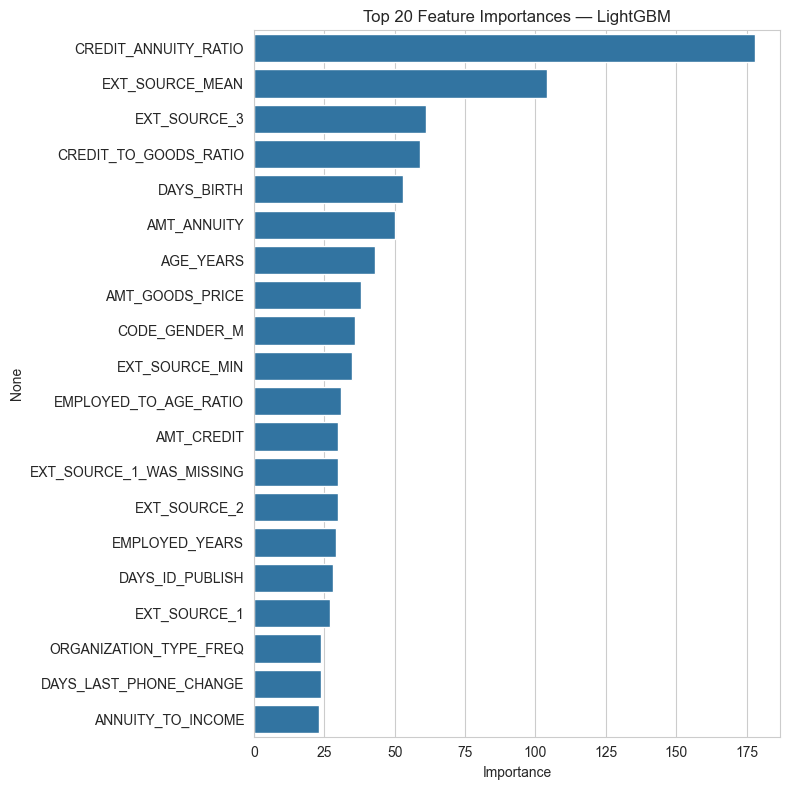

In [19]:
importances = pd.Series(tuned_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plt.figure(figsize=(8,8))
sns.barplot(x=importances.head(20).values, y=importances.head(20).index)
plt.title(f'Top 20 Feature Importances — {best_model_name}')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

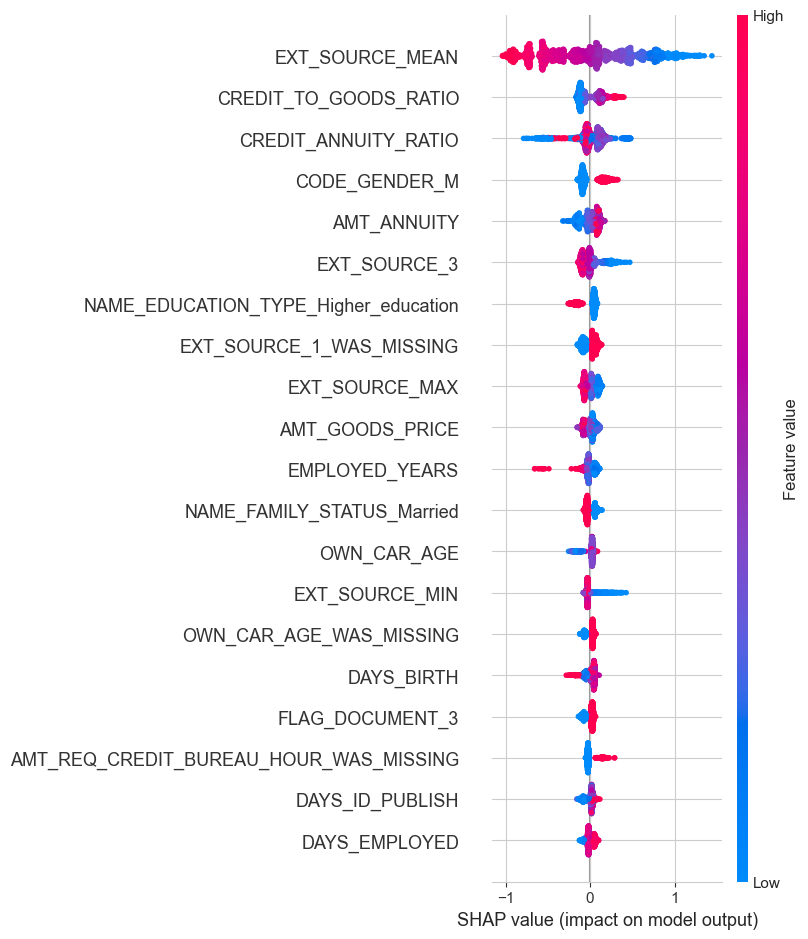

In [20]:
import shap

explainer = shap.TreeExplainer(tuned_model)
# Use a sample for speed
X_sample = X_test.sample(min(2000, len(X_test)), random_state=42)
shap_values = explainer.shap_values(X_sample)

shap.summary_plot(shap_values, X_sample, show=True)

**Observation:** The `EXT_SOURCE_*` features (raw and combined) and the engineered ratio features (`CREDIT_ANNUITY_RATIO`, `DEBT_TO_INCOME`, etc.) typically dominate feature importance — validating that the feature engineering step was worthwhile, not just the choice of model.

## 10. Final Summary

| Stage | What was done |
|---|---|
| Cleaning | Fixed DAYS_EMPLOYED anomaly, dropped low-value building columns, imputed missing values, capped outliers |
| Feature Engineering | Ratio features (debt-to-income, credit-annuity, etc.), EXT_SOURCE combinations, categorical encoding |
| Imbalance Handling | `class_weight='balanced'` / `scale_pos_weight` (no synthetic oversampling needed) |
| Modeling | Logistic Regression, Random Forest, XGBoost, LightGBM compared on ROC-AUC/Precision/Recall/F1 |
| Tuning | RandomizedSearchCV on the best-performing model |
| Explainability | Feature importance + SHAP summary plot |

**Business takeaway:** The model's precision/recall tradeoff can be tuned via the classification threshold — 
in credit risk, missing a defaulter (false negative) is usually costlier than incorrectly flagging a safe 
applicant (false positive), so the threshold should be chosen with that asymmetry in mind rather than 
defaulting to 0.5.

**What this project demonstrates:** the full applied ML lifecycle — cleaning, feature engineering, 
handling imbalanced data, comparing supervised models including boosting algorithms, tuning, and 
explaining the final model — using only what's been covered in the DSMP program so far (no unsupervised 
techniques, no multi-table aggregation).